[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AndresOrdonez369/deepLearningWeek1/blob/main/semana2/proyectos/NB04_redes_que_recuerdan.ipynb)

# NB04 · Redes que recuerdan: RNN, LSTM y un vistazo a la atención
**Neural Networks: Deep Learning · UIDE · Semana 2 · Tema 2** — Docente: Andrés Ordóñez-Bolaños

**La necesidad:** muchos datos llegan **en orden**: las palabras de una frase, los pagos mes a mes de un socio, las ventas de cada día, el audio de una llamada. En el Tema 1 la CNN supuso que **lo cercano importa**. Ahora la pregunta es otra: **¿qué hace una red cuando el orden importa?** ¿Y qué pasa cuando la secuencia es tan larga que lo importante quedó muy atrás?

Vas a ver tres ideas, con datos que entrenan en segundos:
1. Una **red recurrente (RNN)** lee de a un paso y anota lo leído en una **libreta**: su estado oculto.
2. Esa libreta **se olvida**: lo que pasó hace muchos pasos se borra poco a poco. La **LSTM** le pone compuertas para cuidarla.
3. La **atención** no resume: **mira directamente** a todos los pasos y elige cuál importa. Es la idea del Transformer, y la base del debate de la lectura de tendencia («¿El regreso de las redes recurrentes?»).

### Cómo usar este Colab (2 minutos)
**Todo el código ya está escrito: tú lees, predices, ejecutas y comparas.** No tienes que programar nada para avanzar.

1. **Archivo → Guardar una copia en Drive.** Así tus cambios quedan guardados.
2. Ejecuta la celda **Configuración** y después avanza en orden con `Shift + Enter`.
3. Cada parte sigue el mismo orden:
   **Qué vas a hacer → la necesidad → ejemplo → el nombre → la fórmula («Léelo así») → Qué hace este código → 🔮 Antes de ejecutar: ¿qué crees que saldrá? → ejecuta → Qué deberías ver → 💭 Para pensar.**
4. En **🔮 Antes de ejecutar** detente cinco segundos y apuesta un resultado. Acertar no importa; **comparar** sí.
5. En **💭 Para pensar** responde con tu pareja y después abre **Ver respuesta**.
6. Las celdas **🧪 Experimenta** son opcionales: cambia **un solo** valor marcado y vuelve a ejecutar.
7. **No tiene nota.** Trabajen en parejas y equivóquense sin miedo.

> **🛟 Si algo falla**
> - `NameError: name 'x' is not defined` → te saltaste una celda de arriba. Usa **Entorno de ejecución → Ejecutar anteriores** (o **Ejecutar todo**).
> - Un error que menciona `shape` o `expected ndim=3` → las secuencias deben tener forma **(ejemplos, pasos, datos por paso)**. Vuelve a ejecutar la celda original sin cambios.
> - Tus porcentajes difieren un poco de los de «Qué deberías ver» → normal: otra computadora puede redondear distinto. Lo que importa es el patrón (quién aprende y quién adivina).
> - Si cambiaste algo y ya no sabes qué: **Entorno de ejecución → Reiniciar y ejecutar todo**.

### Mapa del Colab
| Parte | Qué aprendes | Lámina |
|---|---|---|
| 0 | Una secuencia es una tabla con orden | 29 |
| 1 | La libreta a mano: cómo se olvida | 31, 32, 34 |
| 2 | El orden importa: promedio contra RNN | 30, 36 |
| 3 | El examen de memoria: SimpleRNN y LSTM con 10, 30 y 80 pasos | 33, 35, 38 |
| 4 | La atención: mirar directo al paso importante | 41, 43 |
| 5 | La atención a mano, con 3 palabras | 42 |
| 🏁 | Resumen · **Para comprobar que entendiste** · **Experimento 4: 50 pasos y dos semillas** | 37 |

En clase (lámina 37): prioridad **1, 2, 3 y 4**. Las partes 0 y 5 son cortas; si no alcanza el tiempo, quedan para casa.

In [1]:
# @title Configuración · ejecuta esta celda primero (no necesitas abrirla)
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")   # hide TensorFlow info messages
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

SEED = 2026
keras.utils.set_random_seed(SEED)
np.set_printoptions(precision=4, suppress=True, linewidth=140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

# The same colors as the slides: amber = gets worse / positive, azure = gets better / negative, mint = learned, coral = error
AMBAR, AZUL, MENTA, CORAL, TINTA, LILA = "#E39A12", "#2B8FD6", "#12A37F", "#E0533D", "#1F2A3A", "#8B6FD1"
COLOR = {"rnn": AZUL, "lstm": MENTA, "atencion": AMBAR}
NOMBRE = {"rnn": "SimpleRNN", "lstm": "LSTM", "atencion": "Atención"}

print("Listo. TensorFlow", tf.__version__, "| Keras", keras.__version__)

Listo. TensorFlow 2.21.0 | Keras 3.15.1


---
## 0 · Una secuencia es una tabla con orden
📽 Lámina 29

**Qué vas a hacer:** fabricar el historial de pagos de 2 500 socios ficticios y ver qué forma tiene una secuencia para Keras.

**El ejemplo:** cada socio tiene **12 meses** de historial; cada mes anotamos cuántos **días de atraso** tuvo en su cuota. Hay dos tipos de socio:
- los que **empeoran** (clase 1): cada mes se atrasan un poco más;
- los que **mejoran** (clase 0): **los mismos meses, al revés**. Empiezan mal y terminan bien.

Fíjate en el truco: un socio que mejora tiene **exactamente los mismos números** que uno que empeora, solo que en otro orden. El **promedio** de atrasos es idéntico. Lo único que los distingue es **el orden**.

**El nombre:** para Keras, un conjunto de secuencias es un bloque de forma **(ejemplos, pasos, datos por paso)**. Aquí: (2 000 socios, 12 meses, 1 dato por mes). Una frase sería (frases, palabras, números por palabra).

**Qué hace este código:**
- `historial(n)` crea `n` socios: un atraso inicial al azar, una pendiente al azar (cuánto empeora por mes) y un poco de ruido. Después elige al azar la clase y, si es «mejora», **invierte** los meses con `x[:, ::-1]`. Divide entre 30 para que los números queden cerca de 0 a 1.
- Crea 2 000 socios para entrenar y 500 para el examen final, e imprime sus formas.
- Dibuja un socio que empeora y el mismo socio al revés.

🔮 **Antes de ejecutar:** ¿qué forma tendrá `X`?

X: (2000, 12, 1) | y: (2000,) | Xt: (500, 12, 1)
promedio de atraso · empeoran: 13.5 días · mejoran: 13.6 días


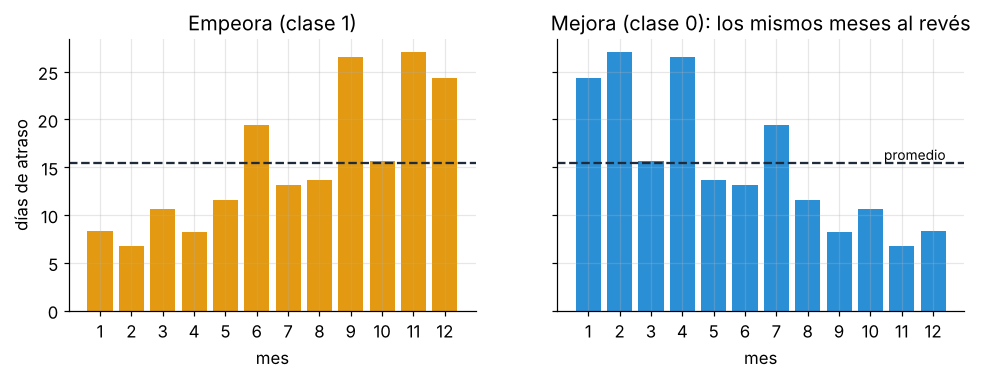

In [2]:
rng = np.random.default_rng(SEED)

def historial(n, meses=12):
    # Days late per month for members whose payments get worse over the year
    inicio = rng.uniform(0, 5, n)                        # days late in the first month
    pend = rng.uniform(1, 3, n)                          # how many more days late each month
    t = np.arange(meses)
    x = np.clip(inicio[:, None] + pend[:, None] * t + rng.normal(0, 3, (n, meses)), 0, None)
    y = rng.integers(0, 2, n)                            # 1 = gets worse, 0 = gets better
    x = np.where(y[:, None] == 1, x, x[:, ::-1])         # "better" = the same months in reverse order
    return x[..., None].astype("float32") / 30, y        # shape (members, months, 1), scaled by 30 days

X, y = historial(2000)                                   # training
Xt, yt = historial(500)                                  # final exam
print("X:", X.shape, "| y:", y.shape, "| Xt:", Xt.shape)
print(f"promedio de atraso · empeoran: {X[y == 1].mean() * 30:.1f} días · mejoran: {X[y == 0].mean() * 30:.1f} días")

uno = X[np.where(y == 1)[0][0], :, 0] * 30
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.2), sharey=True)
axs[0].bar(range(1, 13), uno, color=AMBAR); axs[0].set_title("Empeora (clase 1)")
axs[1].bar(range(1, 13), uno[::-1], color=AZUL); axs[1].set_title("Mejora (clase 0): los mismos meses al revés")
for ax in axs:
    ax.axhline(uno.mean(), color=TINTA, ls="--", lw=1.5); ax.set_xlabel("mes"); ax.set_xticks(range(1, 13))
axs[0].set_ylabel("días de atraso"); axs[1].text(12.4, uno.mean(), "promedio", va="bottom", ha="right", fontsize=9)
plt.show()

**Qué deberías ver:** `X: (2000, 12, 1)`: **2 000 socios, 12 meses, 1 dato por mes**. El promedio de atraso es el mismo en las dos clases (alrededor de 13.6 días). En la gráfica, las dos barras tienen la misma altura promedio (la línea punteada): solo cambia **el orden** de los meses.

### 💭 Para pensar

**1.** Si tuvieras 300 frases de 20 palabras y cada palabra se representa con 8 números, ¿qué forma tendría el bloque?

<details><summary>Ver respuesta</summary>

**(300, 20, 8)**: (ejemplos, pasos, datos por paso).
</details>

**2.** ¿Podría un modelo que solo mira el **promedio** de los 12 meses distinguir a los que empeoran de los que mejoran?

<details><summary>Ver respuesta</summary>

**No**: el promedio es el mismo en las dos clases, porque son los mismos números en otro orden. Lo comprobamos en la Parte 2.
</details>

---
## 1 · La libreta a mano
📽 Láminas 31, 32, 34

**Qué vas a hacer:** calcular con tus propios números cómo una RNN guarda (y olvida) lo que leyó.

**La idea:** una RNN lee la secuencia **de a un paso**. En cada paso combina **lo que llega ahora** con **lo que ya tenía anotado** en su libreta, y reescribe la libreta. La libreta se llama **estado oculto**, $h$.

$$h_t = \tanh\big(w \cdot x_t + u \cdot h_{t-1} + b\big)$$

**Léelo así:** "la libreta nueva ($h_t$) es la tanh de: el dato de este paso ($x_t$) por su peso $w$, más la libreta del paso anterior ($h_{t-1}$) por su peso $u$, más el sesgo". La **tanh** (que vimos en la semana 1) deja el resultado entre −1 y 1. Los pesos $w$, $u$ y $b$ son **los mismos en todos los pasos**: la RNN reutiliza la misma celda, como la CNN reutilizaba el mismo filtro en toda la foto.

### Ejemplo: un solo dato y luego silencio
La secuencia es $x = [1, 0, 0, 0, \dots]$: un dato importante al principio y después nada. Con $w = 1$, $u = 0.5$ y $b = 0$:
- paso 1: $h_1 = \tanh(1 \cdot 1 + 0.5 \cdot 0) = \tanh(1) = 0.76$
- paso 2: $h_2 = \tanh(1 \cdot 0 + 0.5 \cdot 0.76) = \tanh(0.38) = 0.36$
- paso 3: $h_3 = \tanh(0.5 \cdot 0.36) = 0.18$ … y así, cada paso **a la mitad**.

**Qué hace este código:**
- `libreta(x, u)` recorre la secuencia con un `for` y aplica la fórmula en cada paso; guarda el estado de cada paso.
- La aplica con $u = 0.5$ y con $u = 0.9$ (una libreta que «conserva» más) y dibuja cuánto queda del primer dato en cada paso.

🔮 **Antes de ejecutar:** con $u = 0.5$, ¿cuánto quedará del primer dato después de 10 pasos?

u = 0.5 → [0.7616 0.3634 0.1797 0.0896 0.0448 0.0224 0.0112 0.0056 0.0028 0.0014]
u = 0.9 → [0.7616 0.595  0.4896 0.4142 0.3564 0.3102 0.2721 0.2401 0.2128 0.1892]
después de 10 pasos queda: 0.0014 (u = 0.5) y 0.1892 (u = 0.9)


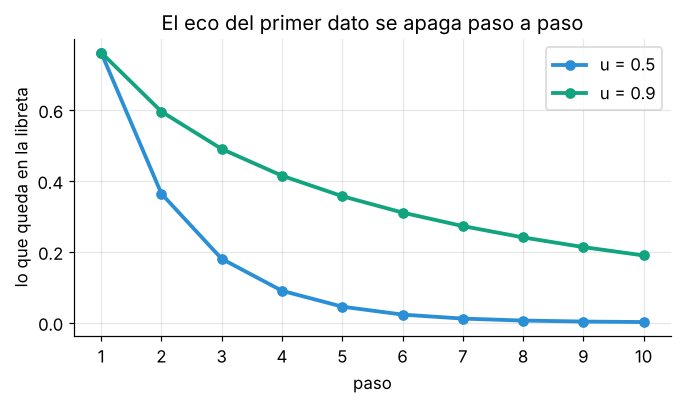

In [3]:
def libreta(x, u=0.5, w=1.0, b=0.0):
    # One-number RNN: the new notebook mixes today's input with yesterday's notebook
    h, estados = 0.0, []
    for x_t in x:
        h = np.tanh(w * x_t + u * h + b)        # the same w, u and b at every step
        estados.append(h)
    return np.array(estados)

x = np.array([1.0] + [0.0] * 9)                 # one important input, then nine steps of silence
h_05 = libreta(x, u=0.5)
h_09 = libreta(x, u=0.9)
print("u = 0.5 →", np.round(h_05, 4))
print("u = 0.9 →", np.round(h_09, 4))
print(f"después de 10 pasos queda: {h_05[-1]:.4f} (u = 0.5) y {h_09[-1]:.4f} (u = 0.9)")

fig, ax = plt.subplots(figsize=(7, 3.5))
pasos = range(1, 11)
ax.plot(pasos, h_05, "o-", color=AZUL, lw=2.5, label="u = 0.5")
ax.plot(pasos, h_09, "o-", color=MENTA, lw=2.5, label="u = 0.9")
ax.set_xlabel("paso"); ax.set_ylabel("lo que queda en la libreta"); ax.set_xticks(list(pasos))
ax.set_title("El eco del primer dato se apaga paso a paso"); ax.legend(); plt.show()

**Qué deberías ver:** con $u = 0.5$, la libreta vale **0.76, 0.36, 0.18, 0.09** en los cuatro primeros pasos, y después de 10 pasos queda casi nada (alrededor de **0.001**). Con $u = 0.9$ se apaga más despacio (queda alrededor de 0.19), pero también se apaga.

**Léelo así:** cada paso multiplica lo anotado por algo menor que 1 (más o menos $u$), así que el recuerdo **se encoge** como $0.5 \times 0.5 \times 0.5 \cdots$. $0.5^{10} \approx 0.001$. Al entrenar pasa lo mismo con la **culpa** que viaja hacia atrás (la retropropagación de la semana 1): en cada paso se multiplica por un número pequeño y llega casi en cero a los primeros pasos. Por eso a una RNN simple le cuesta aprender relaciones **lejanas**. Es el «teléfono dañado» de la semana 1, ahora en el tiempo.

🧪 **Experimenta:** cambia `u=0.9` por `u=1.5` en `h_09 = libreta(x, u=0.9)` y vuelve a ejecutar. La libreta ya no se borra… pero tampoco cambia con nada nuevo: se queda pegada cerca de 0.86. Recordar **y** poder actualizar a la vez es lo difícil.

### 💭 Para pensar

**1.** ¿Qué significa que $w$ y $u$ sean los mismos en todos los pasos?

<details><summary>Ver respuesta</summary>

Que la RNN usa **una sola celda** para toda la secuencia, sea de 12 pasos o de 1 000. Comparte pesos **en el tiempo**, como la CNN comparte el filtro **en el espacio**. Por eso tiene pocos parámetros.
</details>

**2.** Si $u$ fuera 0, ¿qué recordaría la libreta?

<details><summary>Ver respuesta</summary>

**Nada** del pasado: $h_t = \tanh(w \cdot x_t + b)$ depende solo del dato de este paso. Sería una red densa aplicada a cada paso por separado.
</details>

---
## 2 · El orden importa
📽 Láminas 30, 36

**Qué vas a hacer:** entrenar dos modelos con el historial de la Parte 0 y ver cuál distingue a los socios que empeoran.

**Los dos modelos:**
1. **El promedio:** una capa `Dense(8)` mira **cada mes por separado** y `GlobalAveragePooling1D` promedia los 12 resultados. Como un promedio no cambia si reordenas los meses, este modelo **no puede ver el orden**.
2. **La RNN:** `SimpleRNN(8)` lee los 12 meses **en orden** con una libreta de 8 números, y la salida mira la libreta final.

**Las secuencias en Keras:** `keras.Input(shape=(12, 1))` = 12 pasos con 1 dato cada uno. Cambiar de un modelo a otro es cambiar **una línea**.

**Qué hace este código:**
- Arma los dos modelos, cada uno con `keras.utils.set_random_seed(SEED)` antes, para que todos obtengamos los mismos pesos iniciales.
- Los compila igual (Adam con `learning_rate=0.01` y la entropía cruzada binaria de la semana 1), los entrena 15 épocas y los evalúa con los 500 socios del examen final.

🔮 **Antes de ejecutar:** ¿qué exactitud tendrá el modelo del promedio? ¿Y la RNN?

promedio ·  25 parámetros · exactitud en el examen final: 48.4%


rnn      ·  89 parámetros · exactitud en el examen final: 100.0%


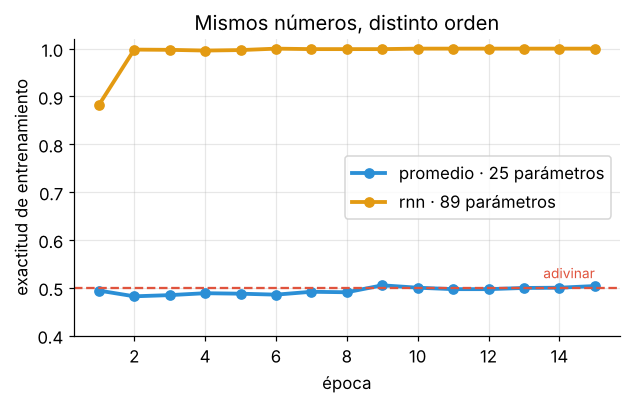

In [4]:
resultados_orden = {}
for nombre in ["promedio", "rnn"]:
    keras.utils.set_random_seed(SEED)
    if nombre == "promedio":
        model = keras.Sequential([
            keras.Input(shape=(12, 1)),                    # 12 months, 1 number per month
            layers.Dense(8, activation="relu"),            # looks at each month on its own
            layers.GlobalAveragePooling1D(),               # averages the 12 months: the order is lost
            layers.Dense(1, activation="sigmoid"),
        ])
    else:
        model = keras.Sequential([
            keras.Input(shape=(12, 1)),
            layers.SimpleRNN(8),                           # reads the months in order with an 8-number notebook
            layers.Dense(1, activation="sigmoid"),
        ])
    model.compile(keras.optimizers.Adam(0.01), "binary_crossentropy", metrics=["accuracy"])
    h = model.fit(X, y, epochs=15, batch_size=32, verbose=0)
    acc = model.evaluate(Xt, yt, verbose=0)[1]
    resultados_orden[nombre] = (model.count_params(), acc, h.history["accuracy"])
    print(f"{nombre:8s} · {model.count_params():3d} parámetros · exactitud en el examen final: {acc:.1%}")

fig, ax = plt.subplots(figsize=(6.4, 3.5))
for nombre, color in [("promedio", AZUL), ("rnn", AMBAR)]:
    ax.plot(range(1, 16), resultados_orden[nombre][2], "o-", color=color, lw=2.5, label=f"{nombre} · {resultados_orden[nombre][0]} parámetros")
ax.axhline(0.5, color=CORAL, ls="--", lw=1.5); ax.text(15, 0.52, "adivinar", color=CORAL, ha="right", fontsize=9)
ax.set_xlabel("época"); ax.set_ylabel("exactitud de entrenamiento"); ax.set_ylim(0.4, 1.02)
ax.set_title("Mismos números, distinto orden"); ax.legend(); plt.show()

**Qué deberías ver:** el modelo del promedio, con **25 parámetros**, se queda en alrededor de **48 %**: lo mismo que lanzar una moneda. La RNN, con **89 parámetros**, llega a **100 %** desde las primeras épocas.

**Léelo así:** los dos modelos ven los mismos números. Solo la RNN ve **en qué orden** llegaron. Su suposición, «el orden importa», es justo la que estos datos necesitan.

**Los 89 parámetros de la RNN:** 8 pesos para el dato de entrada ($w$), 8 × 8 = 64 para la libreta anterior ($u$) y 8 sesgos: 80. Más la salida: 8 + 1 = 9. Total **89**.

### 💭 Para pensar

**1.** ¿Por qué el modelo del promedio no puede pasar del 50 %, aunque lo entrenemos 100 épocas?

<details><summary>Ver respuesta</summary>

Porque para él un socio que empeora y uno que mejora son **idénticos**: mismos meses, mismo promedio. No es falta de entrenamiento: es que su suposición (el orden no importa) no sirve para estos datos.
</details>

**2.** En la semana 1, ¿qué habría hecho una red densa con los 12 meses como 12 columnas?

<details><summary>Ver respuesta</summary>

Podría aprender (cada columna tiene su propio peso, así que «sabe» qué mes es cuál), pero necesita **exactamente 12 meses** siempre. La RNN lee secuencias de **cualquier largo** con la misma celda: un socio de 3 meses o uno de 60.
</details>

---
## 3 · El examen de memoria
📽 Láminas 33, 35, 38

**Qué vas a hacer:** poner a prueba la memoria de dos redes recurrentes con secuencias cada vez más largas.

**El examen:** cada paso trae **dos números**: un valor (+1 o −1) y una **marca** (1 o 0). En cada secuencia, **un solo paso** está marcado, y siempre cae entre los 10 primeros. La respuesta es: **¿el valor del paso marcado era +1?** Después de la marca vienen muchos pasos de distracción. Es como si te dictaran un número al principio de una llamada larga y al final te preguntaran cuál era.

Lo probamos con secuencias de **10, 30 y 80 pasos**: cuanto más larga, más lejos queda la marca del final.

**Las dos redes recurrentes:**
- **`SimpleRNN(32)`**: la libreta de la Parte 1, con 32 números.
- **`LSTM(32)`** (*Long Short-Term Memory*, Hochreiter y Schmidhuber, 1997): una libreta con **tres compuertas** que deciden **qué olvidar** (el borrador), **qué guardar** (el lápiz) y **qué mostrar** (lo que lees en voz alta). Cada compuerta es una sigmoide entre 0 y 1, como una válvula. La idea: si la compuerta de olvidar se queda en 1, lo anotado **pasa intacto** de un paso al siguiente, y la culpa también puede viajar hacia atrás sin apagarse.

$$c_t = f_t \cdot c_{t-1} + i_t \cdot \tilde c_t \qquad\qquad h_t = o_t \cdot \tanh(c_t)$$

**Léelo así:** "la libreta nueva ($c_t$) es lo que **no** borraste de la anterior ($f_t$, olvidar) más lo nuevo que decidiste escribir ($i_t$, guardar); lo que la red muestra ($h_t$) es la parte de la libreta que deja salir la compuerta $o_t$ (mostrar)".

Y una tercera red, que veremos en la Parte 4: la **atención**.

**Qué hace este código:**
- `examen(T, n, rng)` fabrica `n` secuencias de `T` pasos con su marca y su respuesta.
- `modelo(tipo, T)` arma la red: `SimpleRNN(32)`, `LSTM(32)` o la atención (la explicamos en la Parte 4). Todas terminan en `Dense(1, sigmoid)`.
- Para cada largo y cada red: 3 000 secuencias para entrenar y 1 000 para el examen final, **las mismas reglas para todas** (10 épocas, Adam con 0.003, lotes de 64). Tarda alrededor de un minuto.

🔮 **Antes de ejecutar:** con 10 pasos, ¿aprenderán las dos redes recurrentes? ¿Y con 80?

In [5]:
def examen(T, n, rng, K=10):
    # Each step: (value +1/-1, mark 0/1). One of the first K steps is marked; the answer is its value
    v = rng.choice([-1.0, 1.0], size=(n, T)).astype("float32")
    pos = rng.integers(0, K, size=n)                                   # where the mark is
    marca = np.zeros((n, T), dtype="float32"); marca[np.arange(n), pos] = 1
    return np.stack([v, marca], -1), (v[np.arange(n), pos] > 0).astype("int32"), pos

def modelo(tipo, T):
    x = keras.Input((T, 2))                                            # T steps, 2 numbers per step
    if tipo == "atencion":                                             # explained in Part 4
        h = layers.Dense(16, activation="tanh")(x)                     # a summary of each step, on its own
        w = layers.Softmax(axis=1, name="pesos")(layers.Dense(1)(h))   # one score per step -> weights that add up to 1
        o = layers.Dense(1, activation="sigmoid")(layers.Flatten()(layers.Dot(axes=1)([w, h])))   # weighted average
    else:
        recurrente = {"rnn": layers.SimpleRNN, "lstm": layers.LSTM}[tipo]
        o = layers.Dense(1, activation="sigmoid")(recurrente(32)(x))   # reads step by step; the last notebook decides
    return keras.Model(x, o)

memoria, modelos, examenes = {}, {}, {}
for T in [10, 30, 80]:
    memoria[T] = {}
    for tipo in ["rnn", "lstm", "atencion"]:
        r = np.random.default_rng(SEED)
        Xm, ym, _ = examen(T, 3000, r)                                 # training sequences
        Xmt, ymt, pmt = examen(T, 1000, r)                             # final exam
        keras.utils.set_random_seed(SEED)
        m = modelo(tipo, T)
        m.compile(keras.optimizers.Adam(0.003), "binary_crossentropy", metrics=["accuracy"])
        h = m.fit(Xm, ym, epochs=10, batch_size=64, verbose=0)
        memoria[T][tipo] = (m.count_params(), m.evaluate(Xmt, ymt, verbose=0)[1], h.history["accuracy"])
        modelos[(T, tipo)], examenes[T] = m, (Xmt, ymt, pmt)
    print(f"{T:3d} pasos · " + " · ".join(f"{NOMBRE[t]} ({memoria[T][t][0]:,} parámetros): {memoria[T][t][1]:.1%}" for t in memoria[T]))

 10 pasos · SimpleRNN (1,153 parámetros): 99.9% · LSTM (4,513 parámetros): 100.0% · Atención (82 parámetros): 100.0%


 30 pasos · SimpleRNN (1,153 parámetros): 100.0% · LSTM (4,513 parámetros): 100.0% · Atención (82 parámetros): 100.0%


 80 pasos · SimpleRNN (1,153 parámetros): 52.1% · LSTM (4,513 parámetros): 50.0% · Atención (82 parámetros): 100.0%


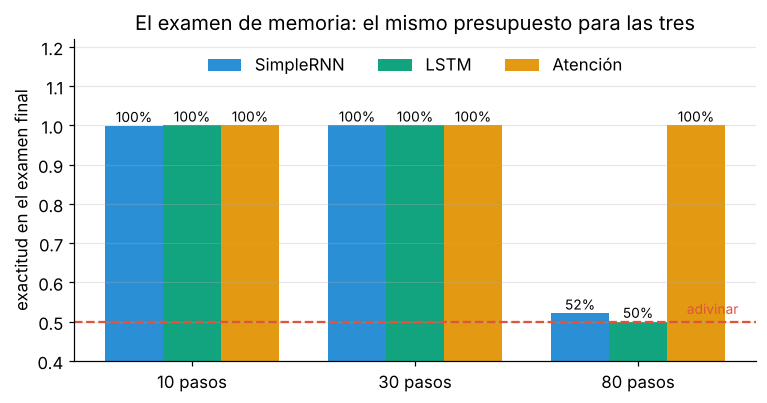

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ancho = 0.26
for k, tipo in enumerate(["rnn", "lstm", "atencion"]):
    accs = [memoria[T][tipo][1] for T in [10, 30, 80]]
    barras = ax.bar(np.arange(3) + (k - 1) * ancho, accs, ancho, color=COLOR[tipo], label=NOMBRE[tipo])
    for b_, a in zip(barras, accs): ax.text(b_.get_x() + b_.get_width() / 2, a + 0.01, f"{a:.0%}", ha="center", fontsize=9)
ax.axhline(0.5, color=CORAL, ls="--", lw=1.5); ax.text(2.45, 0.52, "adivinar", color=CORAL, ha="right", fontsize=9)
ax.set_xticks(range(3)); ax.set_xticklabels(["10 pasos", "30 pasos", "80 pasos"]); ax.set_ylim(0.4, 1.22)
ax.set_ylabel("exactitud en el examen final"); ax.set_title("El examen de memoria: el mismo presupuesto para las tres")
ax.legend(loc="upper center", ncol=3, frameon=False); ax.grid(axis="x", alpha=0); plt.show()

**Qué deberías ver:**

| Pasos | SimpleRNN · 1 153 parámetros | LSTM · 4 513 | Atención · 82 |
|---|---|---|---|
| 10 | ≈ 100 % | 100 % | 100 % |
| 30 | 100 % | 100 % | 100 % |
| 80 | ≈ **52 %** (adivina) | ≈ **50 %** (adivina) | **100 %** |

Con 10 y 30 pasos, las dos redes recurrentes aprueban (la LSTM aprende más rápido: llega a 99 % en la época 3; la SimpleRNN, en la época 6). Con **80 pasos**, con este presupuesto de 10 épocas, **las dos se olvidan** y adivinan. La atención aprueba los tres exámenes con solo **82 parámetros**.

**Léelo así:** la dificultad no es la cantidad de datos, es **la distancia**. Con 80 pasos, la culpa del error tiene que viajar 70 pasos hacia atrás hasta la marca, y en cada paso se debilita (Parte 1). La LSTM ayuda (en traducción y voz fue la reina durante dos décadas), pero tampoco hace magia: con este presupuesto no le alcanza. Una sola corrida no prueba nada: en el Experimento 4 verás que con 50 pasos la LSTM a veces aprende y a veces no, según la semilla.

### 💭 Para pensar

**1.** ¿Por qué una secuencia de 80 pasos es más difícil que una de 10, si la marca siempre está en los 10 primeros?

<details><summary>Ver respuesta</summary>

Porque la red decide **al final**. Con 80 pasos, lo anotado sobre la marca tiene que sobrevivir 70 pasos de distracción en la libreta, y la culpa tiene que viajar 70 pasos hacia atrás para corregir la forma de anotarla. En cada paso se debilita.
</details>

**2.** ¿Qué hace la compuerta de **olvidar** de una LSTM, y por qué ayuda?

<details><summary>Ver respuesta</summary>

Decide cuánto de la libreta anterior se conserva (un número entre 0 y 1). Si se queda cerca de 1, lo anotado **pasa casi intacto** al siguiente paso, en vez de encogerse como en la SimpleRNN.
</details>

**3.** La LSTM tiene casi 4 veces más parámetros que la SimpleRNN. ¿De dónde salen?

<details><summary>Ver respuesta</summary>

De sus **tres compuertas** más el candidato a escribir: cuatro bloques de pesos del mismo tamaño que el de la SimpleRNN. 4 × (32 × (2 + 32) + 32) = 4 480, más la salida (33): **4 513**.
</details>

---
## 4 · La atención: mirar directo al paso importante
📽 Láminas 41, 43

**Qué vas a hacer:** entender la tercera red del examen y ver **a qué pasos miró**.

**La necesidad:** la libreta tiene un tamaño fijo y tiene que **resumir** todo lo leído. ¿Y si en vez de resumir, la red pudiera **volver a mirar** cualquier paso cuando lo necesita?

**El nombre: atención.** En vez de una libreta, la red:
1. resume **cada paso por separado** (`Dense(16)`);
2. le pone a cada paso un **puntaje** de importancia (`Dense(1)`);
3. convierte los puntajes en **pesos que suman 1** con softmax (la del Tema 1, pero sobre los pasos);
4. hace un **promedio ponderado** de los pasos: los de más peso cuentan más (`Dot`).

$$\text{contexto} = \sum_{t=1}^{T} \alpha_t \, h_t \qquad \text{con} \qquad \alpha = \text{softmax}(\text{puntajes})$$

**Léelo así:** "el contexto es la suma de los resúmenes de todos los pasos, cada uno multiplicado por su peso de atención $\alpha_t$; los pesos son los puntajes pasados por softmax, así que son positivos y suman 1". Si un paso tiene peso 0.95, el contexto es casi solo ese paso.

**Los 82 parámetros:** `Dense(16)` sobre 2 números: 2 × 16 + 16 = 48; el puntaje: 16 + 1 = 17; la salida: 16 + 1 = 17. Total **82**. Como **no hay libreta que viaje de paso en paso**, no importa si la marca está a 10 o a 70 pasos del final: la red la mira **directo**. Y como cada paso se calcula por separado, todo se puede hacer **en paralelo**.

**Qué hace este código:**
- Recupera la red de atención entrenada con **80 pasos** y la primera secuencia de su examen final.
- `keras.Model(..., m.get_layer("pesos").output)` arma una red recortada que devuelve los **pesos de atención** de cada paso.
- Dibuja los 80 pesos y marca en rojo el paso que tenía la marca.

🔮 **Antes de ejecutar:** si la red aprendió de verdad, ¿cómo se verán los 80 pesos?

el paso marcado es el 2 · su valor era -1 · la respuesta correcta es 0
peso de atención del paso marcado: 90.3% · suma de los 80 pesos: 1.000
la red dice: 0.2% de que el valor marcado era +1


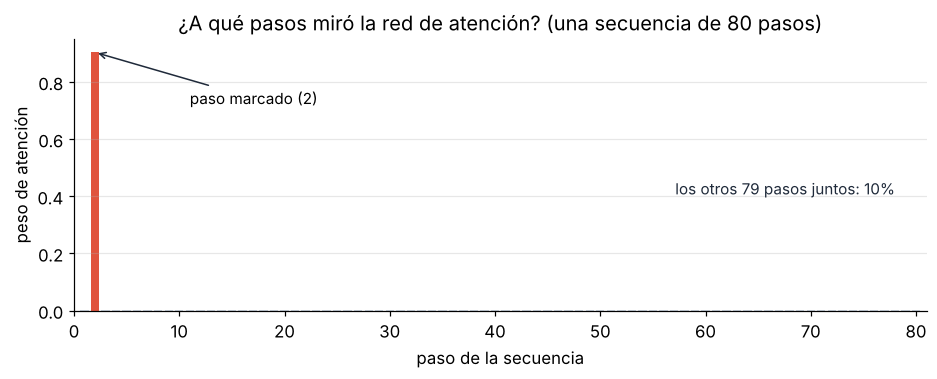

In [7]:
m80 = modelos[(80, "atencion")]
Xmt, ymt, pmt = examenes[80]
ver_pesos = keras.Model(m80.inputs, m80.get_layer("pesos").output)       # the network cut at the attention weights
pesos = ver_pesos.predict(Xmt[:1], verbose=0)[0, :, 0]
p = float(m80.predict(Xmt[:1], verbose=0)[0, 0])

print(f"el paso marcado es el {pmt[0] + 1} · su valor era {int(Xmt[0, pmt[0], 0]):+d} · la respuesta correcta es {ymt[0]}")
print(f"peso de atención del paso marcado: {pesos[pmt[0]]:.1%} · suma de los 80 pesos: {pesos.sum():.3f}")
print(f"la red dice: {p:.1%} de que el valor marcado era +1")

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(range(1, 81), pesos, color=[CORAL if t == pmt[0] else "#C9D3DE" for t in range(80)])
ax.annotate(f"paso marcado ({pmt[0] + 1})", (pmt[0] + 1, pesos[pmt[0]]), xytext=(pmt[0] + 10, pesos[pmt[0]] * 0.8),
            arrowprops=dict(arrowstyle="->", color=TINTA), fontsize=10)
ax.text(78, pesos[pmt[0]] * 0.45, f"los otros 79 pasos juntos: {1 - pesos[pmt[0]]:.0%}", ha="right", fontsize=10, color=TINTA)
ax.set_xlabel("paso de la secuencia"); ax.set_ylabel("peso de atención"); ax.set_xlim(0, 81)
ax.set_title("¿A qué pasos miró la red de atención? (una secuencia de 80 pasos)"); ax.grid(axis="x", alpha=0); plt.show()

**Qué deberías ver:** casi todo el peso cae en **un solo paso**, el marcado: alrededor de **90 %**. Los otros 79 pasos se reparten el resto, con pesos cercanos a 0, y los 80 pesos suman 1. La red responde correctamente con mucha seguridad (en esta secuencia el valor marcado era −1 y la red da apenas 0.2 % de que fuera +1).

**Léelo así:** la atención no tuvo que **recordar** nada a lo largo de 80 pasos: aprendió **a quién mirar**. Por eso los modelos de lenguaje actuales (los Transformers) usan atención: pueden consultar cualquier palabra del texto con precisión.

**¿Entonces la atención siempre gana?** No. Tiene un precio: aquí cada paso tiene un solo puntaje, pero en un Transformer **cada palabra mira a todas las demás**, y eso crece con el **cuadrado** de la longitud (1 000 palabras → 1 000 000 de comparaciones). Por eso la lectura de tendencia cuenta que los modelos **híbridos** mezclan las dos ideas: capas recurrentes baratas que toman apuntes de casi todo y unas pocas capas de atención que **vuelven al libro** por el dato exacto.

### 💭 Para pensar

**1.** ¿Por qué a la red de atención le da igual que la secuencia tenga 10 u 80 pasos?

<details><summary>Ver respuesta</summary>

Porque no pasa un recuerdo de paso en paso: pone un puntaje a **cada paso** y mira directo al importante. La distancia hasta el final no existe para ella.
</details>

**2.** Si la atención es tan buena, ¿por qué los laboratorios vuelven a usar capas recurrentes (lectura de tendencia)?

<details><summary>Ver respuesta</summary>

Por el **costo**: en un Transformer cada palabra se compara con todas las anteriores y guarda memoria de cada una; con textos de cientos de miles de palabras es carísimo. La libreta de una RNN cuesta lo mismo en cada paso. Los híbridos buscan lo mejor de los dos.
</details>

---
## 5 · La atención a mano, con 3 palabras
📽 Lámina 42

**Qué vas a hacer:** calcular con números pequeños cómo decide una palabra a quién mirar, como en un Transformer.

**El ejemplo (de la lectura):** «el socio pagó la cuota porque **él** recibió su sueldo». ¿A quién se refiere «él»: al socio o a la cuota? Una persona lo sabe sin pensar. La atención lo calcula.

**Los nombres: consulta, claves y valores.** Piensa en una biblioteca:
- la **consulta** es lo que buscas («él» busca **una persona**);
- cada palabra tiene una **clave**, como la ficha del catálogo que dice de qué trata;
- y un **valor**, el libro que te llevas si esa ficha coincide.

Usamos vectores de 2 números: **[qué tan persona, qué tan dinero]**. Los escribimos a mano; en un Transformer real, la red los **aprende**.

| Palabra | Clave | Valor |
|---|---|---|
| socio | [2, 0] | [1, 0] (una persona) |
| cuota | [0, 2] | [0, 1] (dinero) |
| él | [1, 0] | [0.5, 0.5] (un pronombre: todavía no sabemos de qué) |

La **consulta** de «él» es [1.5, 0]: busca una persona.

$$\text{puntaje} = \text{consulta}\cdot\text{clave} \qquad \alpha = \text{softmax}(\text{puntajes}) \qquad \text{nuevo «él»} = \sum \alpha \cdot \text{valor}$$

**Léelo así:** "el puntaje de cada palabra es qué tanto coincide su clave con la consulta (el producto punto de la semana 1); softmax convierte los puntajes en pesos que suman 1; y el nuevo significado de «él» es el promedio de los valores, ponderado por esos pesos".

**Qué hace este código:** calcula los 3 puntajes con `claves @ consulta`, los pasa por softmax, mezcla los valores y dibuja los pesos.

🔮 **Antes de ejecutar:** ¿qué palabra tendrá el puntaje más alto? ¿Cuánto peso le quedará a «cuota»?

socio  puntaje 3.0 → peso 78.6%
cuota  puntaje 0.0 → peso 3.9%
él     puntaje 1.5 → peso 17.5%
«él» antes de mirar: [0.5 0.5] → después de mirar: [0.873 0.127]  [persona, dinero]


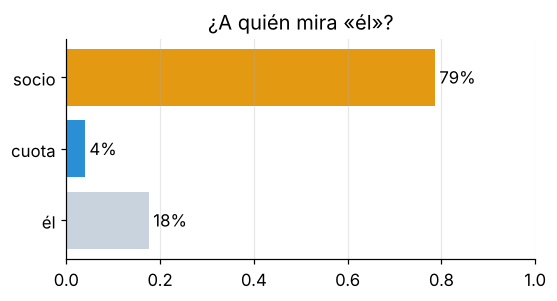

In [8]:
palabras = ["socio", "cuota", "él"]
claves = np.array([[2.0, 0.0],        # socio: a person
                   [0.0, 2.0],        # cuota: money
                   [1.0, 0.0]])       # él: a little bit of person
valores = np.array([[1.0, 0.0],
                    [0.0, 1.0],
                    [0.5, 0.5]])      # "él" alone is ambiguous
consulta = np.array([1.5, 0.0])       # what "él" is looking for: a person

puntajes = claves @ consulta                           # dot product of the query with every key
pesos_a = np.exp(puntajes) / np.exp(puntajes).sum()    # softmax: positive weights that add up to 1
nuevo_el = pesos_a @ valores                           # weighted average of the values

for pal, s, a in zip(palabras, puntajes, pesos_a):
    print(f"{pal:6s} puntaje {s:.1f} → peso {a:.1%}")
print("«él» antes de mirar:", valores[2], "→ después de mirar:", np.round(nuevo_el, 3), " [persona, dinero]")

fig, ax = plt.subplots(figsize=(5.5, 2.6))
ax.barh(palabras, pesos_a, color=[AMBAR, AZUL, "#C9D3DE"]); ax.invert_yaxis(); ax.set_xlim(0, 1)
for i, a in enumerate(pesos_a): ax.text(a + 0.01, i, f"{a:.0%}", va="center")
ax.set_title("¿A quién mira «él»?"); ax.grid(axis="y", alpha=0); plt.show()

**Qué deberías ver:** puntajes **3.0** (socio), **0.0** (cuota) y **1.5** (él). Después de softmax: **socio ≈ 79 %**, **cuota ≈ 4 %** y él ≈ 17.5 %. El nuevo «él» pasa de [0.5, 0.5] (ambiguo) a alrededor de **[0.87, 0.13]**: casi pura persona. La atención resolvió a quién se refiere.

**Así funciona un Transformer**, a lo grande: cada palabra calcula su consulta, su clave y su valor (multiplicando su vector por matrices **aprendidas**), y **todas las palabras miran a todas a la vez**. Con $n$ palabras son $n \times n$ puntajes: 3 × 3 = 9 aquí, pero **1 000 × 1 000 = 1 000 000** en un texto de mil palabras. Ese es el precio de la atención.

<details><summary>Para curiosos: dos detalles del Transformer real</summary>

1. Antes de softmax, los puntajes se dividen entre $\sqrt{d}$ (la raíz del tamaño de los vectores) para que no se disparen cuando los vectores son largos.
2. No hay una sola atención sino varias «cabezas» en paralelo, cada una con sus propias consultas y claves: una puede buscar a quién se refiere un pronombre y otra, qué verbo va con qué sujeto.
</details>

### 💭 Para pensar

**1.** Si la consulta de «él» fuera [0, 1.5] (buscando dinero), ¿a qué palabra miraría más?

<details><summary>Ver respuesta</summary>

A **«cuota»**: su clave [0, 2] coincide con la consulta (puntaje 3.0) y la de «socio» no (0.0).
</details>

**2.** ¿Cuántos puntajes calcula la atención para una frase de 10 palabras en la que todas miran a todas? ¿Y para 100?

<details><summary>Ver respuesta</summary>

10 × 10 = **100**; con 100 palabras, 100 × 100 = **10 000**. Diez veces más palabras, **cien veces más** cuentas: crece con el cuadrado.
</details>

---
## Resumen en 5 líneas
1. Una **secuencia** es un bloque de forma **(ejemplos, pasos, datos por paso)**, y a veces **el orden es lo único que importa** (promedio: 48 %; RNN: 100 %).
2. Una **RNN** lee de a un paso y anota en una **libreta** (estado oculto) con **la misma celda** en cada paso: $h_t = \tanh(w x_t + u h_{t-1} + b)$.
3. La libreta **se olvida**: el eco del primer dato se encoge en cada paso (0.76, 0.36, 0.18, 0.09…), y la culpa que viaja hacia atrás también. La **LSTM** le pone compuertas (olvidar, guardar, mostrar).
4. Con 80 pasos, SimpleRNN y LSTM adivinan con nuestro presupuesto; la **atención** (82 parámetros) aprueba porque **mira directo** al paso importante.
5. La atención tiene un precio que crece con el **cuadrado** de la longitud. Por eso la tendencia son los **híbridos**: apuntes recurrentes baratos + unas pocas capas de atención.

---
## 🏁 Para comprobar que entendiste
Responde cada pregunta **antes** de abrir la respuesta. Si fallas alguna, vuelve a la parte indicada.

### 💭 Preguntas

**1.** ¿Qué forma tiene `X` en el historial de pagos, y qué significa cada número?

<details><summary>Ver respuesta</summary>

`(2000, 12, 1)`: 2 000 socios, 12 meses (pasos), 1 dato por mes. (Parte 0)
</details>

**2.** Con $w = 1$, $u = 0.5$ y $b = 0$, la libreta vale 0.76 después del primer dato. ¿Cuánto vale un paso después, si el siguiente dato es 0?

<details><summary>Ver respuesta</summary>

$\tanh(0.5 \cdot 0.76) = \tanh(0.38) \approx$ **0.36**: casi la mitad. (Parte 1)
</details>

**3.** ¿Qué significa que una RNN «comparte pesos en el tiempo»?

<details><summary>Ver respuesta</summary>

Que usa **la misma celda** (los mismos $w$, $u$ y $b$) en todos los pasos, igual que la CNN usa el mismo filtro en toda la foto. Por eso puede leer secuencias de cualquier largo con pocos parámetros. (Parte 1)
</details>

**4.** ¿Por qué el modelo del promedio se quedó en 48 % con el historial de pagos?

<details><summary>Ver respuesta</summary>

Porque un socio que mejora tiene **los mismos meses** que uno que empeora, al revés: el promedio es idéntico. Solo el **orden** los distingue, y el promedio lo borra. (Parte 2)
</details>

**5.** ¿Cuántos parámetros tiene `SimpleRNN(8)` con 1 dato por paso? Muestra la cuenta.

<details><summary>Ver respuesta</summary>

Entrada: 1 × 8 = 8; libreta anterior: 8 × 8 = 64; sesgos: 8. Total **80** (más 9 de la salida: 89). (Parte 2)
</details>

**6.** En el examen de memoria, ¿qué cambia entre 10 y 80 pasos, si la marca siempre está entre los 10 primeros?

<details><summary>Ver respuesta</summary>

La **distancia** hasta el final, donde la red decide. Con 80 pasos, el recuerdo y la culpa tienen que atravesar hasta 70 pasos de distracción, y se debilitan en cada uno. (Parte 3)
</details>

**7.** Nombra las tres compuertas de la LSTM y di qué hace cada una.

<details><summary>Ver respuesta</summary>

**Olvidar**: cuánto de la libreta anterior se conserva. **Guardar**: cuánto de lo nuevo se escribe. **Mostrar**: qué parte de la libreta sale como resultado del paso. Cada una es una sigmoide entre 0 y 1. (Parte 3)
</details>

**8.** ¿Por qué la red de atención aprueba con 80 pasos, y con solo 82 parámetros?

<details><summary>Ver respuesta</summary>

Porque no pasa un recuerdo de paso en paso: pone un **puntaje a cada paso**, los convierte en pesos con softmax y **mira directo** al marcado (casi todo su peso cae ahí). (Parte 4)
</details>

**9.** En el ejemplo de «él», ¿qué hace softmax con los puntajes 3.0, 0.0 y 1.5?

<details><summary>Ver respuesta</summary>

Los convierte en **pesos positivos que suman 1**: ≈ 79 %, 4 % y 17 %. El más alto se lleva casi todo. (Parte 5)
</details>

**10.** Si un texto pasa de 1 000 a 10 000 palabras, ¿cuánto crece el número de comparaciones de la atención? ¿Y el tamaño de la libreta de una RNN?

<details><summary>Ver respuesta</summary>

Las comparaciones crecen **100 veces** (de 1 millón a 100 millones): con el cuadrado. La libreta de la RNN **no crece**: tiene tamaño fijo. Ese es el debate de la lectura de tendencia. (Partes 4 y 5)
</details>

---
### 🧪 Experimento 4 (opcional): 50 pasos y dos semillas
📽 Lámina 37

**La pregunta:** con 30 pasos las dos redes recurrentes aprobaron y con 80 las dos adivinaron. ¿Y con **50**? ¿Una sola corrida basta para decidir?

**Qué hace este código:**
- `pasos = 50` fija el largo de las secuencias y `semilla = 2026` decide **todo el azar**: los datos y los pesos iniciales.
- Entrena SimpleRNN, LSTM y atención con las mismas reglas del examen y muestra la exactitud final y la época en la que pasaron del 90 % (si pasaron).

🔮 **Antes de ejecutar:** ¿crees que el resultado cambiará si solo cambias la semilla?

In [9]:
pasos = 50                      # sequence length
semilla = 2026                  # all the randomness: data and initial weights   (🧪 try 7)

r = np.random.default_rng(semilla)
Xe, ye, _ = examen(pasos, 3000, r)
Xet, yet, _ = examen(pasos, 1000, r)
for tipo in ["rnn", "lstm", "atencion"]:
    keras.utils.set_random_seed(semilla)
    m = modelo(tipo, pasos)
    m.compile(keras.optimizers.Adam(0.003), "binary_crossentropy", metrics=["accuracy"])
    h = m.fit(Xe, ye, epochs=10, batch_size=64, verbose=0)
    epoca = next((e + 1 for e, a in enumerate(h.history["accuracy"]) if a > 0.9), None)
    print(f"{NOMBRE[tipo]:10s} · exactitud en el examen: {m.evaluate(Xet, yet, verbose=0)[1]:.1%} · pasó del 90 % en la época: {epoca or 'nunca'}")

SimpleRNN  · exactitud en el examen: 58.9% · pasó del 90 % en la época: nunca


LSTM       · exactitud en el examen: 48.1% · pasó del 90 % en la época: nunca


Atención   · exactitud en el examen: 100.0% · pasó del 90 % en la época: 4


**Qué deberías ver:** con `semilla = 2026`, la SimpleRNN se queda en alrededor de **59 %** y la LSTM en alrededor de **48 %**: las dos fallan. La atención, **100 %**.

Con `semilla = 7`, la **LSTM aprende** (alrededor de **100 %**, pasa del 90 % en la época 9) y la SimpleRNN sigue en alrededor de **50 %**.

🧪 **Experimenta:** cambia `semilla = 2026` por `7` y ejecuta otra vez.

**Léelo así:** con 50 pasos la LSTM está **en el borde**: según el azar de los datos y de los pesos iniciales, aprende o no. Una sola corrida no prueba que una arquitectura sea mejor que otra. Es la misma advertencia de la lectura de tendencia: antes de declarar un ganador, hay que **repetir** y **comparar con justicia**.

### 💭 Para pensar

**1.** Si solo hubieras corrido la semilla 2026, ¿qué habrías concluido de la LSTM? ¿Y con la 7?

<details><summary>Ver respuesta</summary>

Con 2026, que la LSTM no sirve para 50 pasos; con 7, que sí. Las dos conclusiones serían **apresuradas**: hacen falta varias corridas (varias semillas) y mirar el promedio y la variación.
</details>

**2.** ¿Qué otra cosa podrías cambiar para darle una oportunidad justa a la LSTM?

<details><summary>Ver respuesta</summary>

Más **épocas**, otro `learning_rate` o más datos, **uno a la vez** y probando con varias semillas. Con 10 épocas le dimos poco presupuesto; la atención lo resolvió antes, pero eso no dice que la LSTM no pueda.
</details>

---
**¿Te quedó alguna duda?** Repasa las slides interactivas y la guía de estudio desde la página del curso (Semana 2), y juega el **quiz final**. Para pensar en tu proyecto: **¿tus datos son una tabla, una imagen, una secuencia o un grafo? ¿Qué suposición necesitas?**